In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

import scipy
from scipy.stats import shapiro

import joblib

import os

RUL_CAP = 125
N_OP_CONDITIONS = 6
SENSOR_SELECTED = 21

In [2]:
RED    = '#E74C3C'   # merah cerah → SVR
GREEN  = '#27AE60'   # hijau cerah → GBT  
YELLOW = '#F1C40F'   # kuning → RF
NAVY   = '#0000CD'   # aktual RUL (garis referensi)
AMBER  = '#7D6608'   # ideal fit line
STEEL  = '#566573'   # label/grid
LGRAY  = '#AAB7B8'   # grid lines

DOT_COLORS  = [NAVY, GREEN, RED]   # RF, GBT, SVR
MODEL_NAMES = ['Random Forest', 'Gradient Boosting', 'SVR']

mpl.rcParams.update({
    'font.family'       : 'DejaVu Sans',
    'font.size'         : 10,
    'axes.titlesize'    : 10,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 9,
    'axes.labelcolor'   : STEEL,
    'axes.linewidth'    : 0.8,
    'axes.edgecolor'    : STEEL,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.grid'         : True,
    'grid.color'        : LGRAY,
    'grid.linewidth'    : 0.4,
    'grid.linestyle'    : '--',
    'grid.alpha'        : 0.4,
    'xtick.labelsize'   : 8,
    'ytick.labelsize'   : 8,
    'xtick.color'       : STEEL,
    'ytick.color'       : STEEL,
    'legend.fontsize'   : 8,
    'legend.framealpha' : 0.85,
    'legend.edgecolor'  : LGRAY,
    'figure.dpi'        : 300,
    'savefig.dpi'       : 300,
    'savefig.bbox'      : 'tight',
    'savefig.pad_inches': 0.08,
})

In [ ]:
plot_dir = r'D:/Research Paper/Image'
os.makedirs(plot_dir, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(plot_dir, filename), dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
sensor_mapping = {
    'op_setting_1': 'altitude',
    'op_setting_2': 'mach_num',
    'op_setting_3': 'sea_lv_temp',
    'sensor_1': 'T2',
    'sensor_2': 'T24',
    'sensor_3': 'T30',
    'sensor_4': 'T50',
    'sensor_5': 'P2',
    'sensor_6': 'P15',
    'sensor_7': 'P30',
    'sensor_8': 'Nf',
    'sensor_9': 'Nc',
    'sensor_10': 'epr',
    'sensor_11': 'Ps30',
    'sensor_12': 'phi',
    'sensor_13': 'NRf',
    'sensor_14': 'NRc',
    'sensor_15': 'BPR',
    'sensor_16': 'farB',
    'sensor_17': 'htBleed',
    'sensor_18': 'Nf_dmd',
    'sensor_19': 'PCNfR_dmd',
    'sensor_20': 'W31',
    'sensor_21': 'W32'
}

cols_data = (['unit_id', 'cycle'] +
        [f'op_setting_{i}' for i in range(1,4)] +
        [f'sensor_{i}' for i in range(1,22)])

sensor_cols = ['T2', 'T24', 'T30', 'T50',
          'P2', 'P15', 'P30', 'Nf',
          'Nc', 'epr', 'Ps30', 'phi',
          'NRf', 'NRc', 'BPR', 'farB',
          'htBleed', 'Nf_dmd', 'PCNfR_dmd',
          'W31', 'W32']

op_cols = ['altitude','mach_num','sea_lv_temp']

meta_cols = ['unit_id','cycle','op_condition','RUL']

train_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/train_FD004.txt",
    sep = ' ', header=None
)

test_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/test_FD004.txt",
    sep = ' ', header=None
)

rul_acq = pd.read_csv(
    r"D:/Research Paper/Data/C-MAPSS/RUL_FD004.txt",
    header=None, names = ['RUL_init']
)

train_acq = train_acq.dropna(axis=1)
test_acq = test_acq.dropna(axis=1)
rul_acq = rul_acq.dropna().reset_index(drop=True)

train_acq.columns = cols_data
test_acq.columns = cols_data

train_acq = train_acq.rename(columns=sensor_mapping)
test_acq = test_acq.rename(columns=sensor_mapping)

max_cycle = train_acq.groupby('unit_id')['cycle'].max().reset_index()
max_cycle.columns = ['unit_id','max_cycle']

train_acq = train_acq.merge(max_cycle, on ='unit_id')

train_acq['RUL'] = train_acq['max_cycle'] - train_acq['cycle']

train_acq.drop(columns=['max_cycle'], inplace = True)

rul_acq = rul_acq.dropna().reset_index(drop=True)
rul_acq['unit_id'] = rul_acq.index + 1

max_cycle = test_acq.groupby('unit_id')['cycle'].max().reset_index(name='max_cycle')
test_acq = test_acq.merge(max_cycle, on='unit_id')
test_acq = test_acq.merge(rul_acq, on='unit_id')

test_acq['RUL'] = test_acq['RUL_init'] + (test_acq['max_cycle'] - test_acq['cycle'])
test_acq = test_acq.drop(columns=['max_cycle', 'RUL_init'])

train_s = train_acq.copy()
test_s = test_acq.copy()

for df in [train_s, test_s]:
    df['altitude'] = df['altitude'].round(1)
    df['mach_num'] = df['mach_num'].round(2)
    df['sea_lv_temp'] = df['sea_lv_temp'].round(0)

op_condition_map = (
    train_s[op_cols]
    .drop_duplicates()
    .sort_values(op_cols)
    .reset_index(drop=True)
)

op_condition_map['op_condition'] = op_condition_map.index

train_s = train_s.merge(op_condition_map, on = op_cols, how = 'left')
test_s = test_s.merge(op_condition_map, on = op_cols, how = 'left')

train_sc = train_s.copy()
test_sc = test_s.copy()

scaler_sensor_per_cond = {}

for cond in sorted(train_s['op_condition'].unique()):

    idx_train = train_s['op_condition'] == cond
    idx_test = test_s['op_condition'] == cond

    scaler = MinMaxScaler()
    scaler.fit(train_sc.loc[idx_train, sensor_cols])

    train_sc.loc[idx_train, sensor_cols] = scaler.transform(
        train_s.loc[idx_train, sensor_cols])
    if idx_test.sum() > 0:
        test_sc.loc[idx_test, sensor_cols] = scaler.transform(
            test_s.loc[idx_test, sensor_cols])

    scaler_sensor_per_cond[cond] = scaler

scaler_op_global = MinMaxScaler()
scaler_op_global.fit(train_s[op_cols])

train_sc[op_cols] = scaler_op_global.transform(train_s[op_cols])
test_sc[op_cols] = scaler_op_global.transform(test_s[op_cols])

train_rul_cap = train_sc.copy()
test_rul_cap = test_sc.copy()

def apply_rul_clipping(df, rul_max=RUL_CAP):
    df = df.copy()
    df['RUL'] = df['RUL'].clip(upper=RUL_CAP)
    return df

train_rul_cap = apply_rul_clipping(train_rul_cap, rul_max=RUL_CAP)
test_rul_cap = apply_rul_clipping(test_rul_cap,  rul_max=RUL_CAP)

def build_temporal_features(df, sensor_cols, unit_col='unit_id', cycle_col='cycle'):
    df = df.sort_values([unit_col, cycle_col]).copy()
    new_features = {}

    for sensor in sensor_cols:
        g = df.groupby(unit_col)[sensor]
        new_features[f'{sensor}_lag1']    = g.shift(1)
        new_features[f'{sensor}_rmean10'] = g.transform(
            lambda x: x.rolling(10, min_periods=1).mean())
        new_features[f'{sensor}_ewm3']    = g.transform(
            lambda x: x.ewm(alpha=0.3, adjust=False).mean())
        new_features[f'{sensor}_rstd10']  = g.transform(
            lambda x: x.rolling(10, min_periods=1).std())
        new_features[f'{sensor}_max10']  = g.transform(
            lambda x: x.rolling(10, min_periods=1).max())
        new_features[f'{sensor}_min10']  = g.transform(
            lambda x: x.rolling(10, min_periods=1).min())
    return pd.concat([df, pd.DataFrame(new_features, index=df.index)], axis=1)

train_model = build_temporal_features(train_rul_cap, sensor_cols)
test_model  = build_temporal_features(test_rul_cap,  sensor_cols)

train_model = train_model.fillna(0)
test_model  = test_model.fillna(0)

C:\Users\acer\AppData\Local\Temp\ipykernel_408\4097521916.py:120: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.33333333 0.25       0.25       ... 0.5        0.75       0.66666667]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  train_sc.loc[idx_train, sensor_cols] = scaler.transform(
C:\Users\acer\AppData\Local\Temp\ipykernel_408\4097521916.py:123: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.25       0.25       0.25       ... 0.58333333 0.66666667 0.75      ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  test_sc.loc[idx_test, sensor_cols] = scaler.transform(


In [5]:
groups = train_model['unit_id'] 

drop_cols = ['unit_id', 'cycle', 'op_condition', 'RUL']

X_train = train_model.drop(columns=drop_cols)
y_train = train_model['RUL']

X_test  = test_model.drop(columns=drop_cols)
y_test  = test_model['RUL']

In [ ]:
rf = joblib.load(
    r'D:/Research Paper/Model/best_rf.pkl'
    )

gbt = joblib.load(
    r'D:/Research Paper/Model/best_gbt.pkl'
    )

svr = joblib.load(
    r'D:/Research Paper/Model/best_svr.pkl'
    )

print(type(rf))
print(type(gbt))
print(type(svr))

y_pred_rf_train  = rf.predict(X_train)
y_pred_rf_test   = rf.predict(X_test)

y_pred_gbt_train  = gbt.predict(X_train)
y_pred_gbt_test   = gbt.predict(X_test)

y_pred_svr_train  = svr.predict(X_train)
y_pred_svr_test   = svr.predict(X_test)

<class 'sklearn.ensemble._forest.RandomForestRegressor'>
<class 'sklearn.ensemble._gb.GradientBoostingRegressor'>
<class 'sklearn.svm._classes.SVR'>


In [ ]:
rf = joblib.load(
    r'D:/Research Paper/Model/best_rf.pkl'
    )

print(type(rf))

y_pred_rf_train  = rf.predict(X_train)
y_pred_rf_test   = rf.predict(X_test)

def nasa_score(y_true, y_pred):
    diff = y_pred - y_true
    return np.sum(np.where(diff < 0, np.exp(-diff/13) - 1, np.exp(diff/10) - 1))

models = {
    'RF' : (y_pred_rf_train,  y_pred_rf_test),
}

test_s_sorted = test_s.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
test_model_sorted = test_model.sort_values(['unit_id', 'cycle']).reset_index(drop=True)

assert (test_s_sorted['unit_id'].values == test_model_sorted['unit_id'].values).all()
assert (test_s_sorted['cycle'].values == test_model_sorted['cycle'].values).all()

y_test = test_s_sorted['RUL'].values

for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")
    print(f"  RMSE Train : {root_mean_squared_error(y_train, ytr):.4f}")
    print(f"  MAE  Train : {mean_absolute_error(y_train, ytr):.4f}")
    print(f"  RMSE Test  : {root_mean_squared_error(y_test,  yte):.4f}")
    print(f"  MAE  Test  : {mean_absolute_error(y_test,  yte):.4f}")
    print(f"  NASA Score : {nasa_score(y_test, yte):.4f}")

y_test = test_s_sorted['RUL'].values

for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")
    
    mask_train = y_train <= 125
    mask_test  = y_test <= 125
    
    y_train_filtered = y_train[mask_train]
    ytr_filtered     = ytr[mask_train]
    
    y_test_filtered  = y_test[mask_test]
    yte_filtered     = yte[mask_test]
    
    rmse_train = root_mean_squared_error(y_train_filtered, ytr_filtered)
    mae_train  = mean_absolute_error(y_train_filtered, ytr_filtered)
    
    rmse_test  = root_mean_squared_error(y_test_filtered, yte_filtered)
    mae_test   = mean_absolute_error(y_test_filtered, yte_filtered)
    
    nasa_test  = nasa_score(y_test_filtered, yte_filtered)
    
    print(f"  RMSE Train (RUL <= 125) : {rmse_train:.4f}")
    print(f"  MAE  Train (RUL <= 125) : {mae_train:.4f}")
    print(f"  RMSE Test  (RUL <= 125) : {rmse_test:.4f}")
    print(f"  MAE  Test  (RUL <= 125) : {mae_test:.4f}")
    print(f"  NASA Score (RUL <= 125) : {nasa_test:.4f}")

<class 'sklearn.ensemble._forest.RandomForestRegressor'>

── RF ──
  RMSE Train : 11.4727
  MAE  Train : 7.6781
  RMSE Test  : 109.0353
  MAE  Test  : 79.5710
  NASA Score : 3732610079579172.5000

── RF ──
  RMSE Train (RUL <= 125) : 11.4727
  MAE  Train (RUL <= 125) : 7.6781
  RMSE Test  (RUL <= 125) : 22.8322
  MAE  Test  (RUL <= 125) : 17.8817
  NASA Score (RUL <= 125) : 261313.4834


In [52]:
def nasa_score(y_true, y_pred):
    diff = y_pred - y_true
    return np.sum(np.where(diff < 0, np.exp(-diff/13) - 1, np.exp(diff/10) - 1))

models = {
    'RF' : (y_pred_rf_train,  y_pred_rf_test),
    'GBT' : (y_pred_gbt_train,  y_pred_gbt_test),
    'SVR' : (y_pred_svr_train,  y_pred_svr_test)
}


for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")
    print(f"  RMSE Train : {root_mean_squared_error(y_train, ytr):.4f}")
    print(f"  MAE  Train : {mean_absolute_error(y_train, ytr):.4f}")
    print(f"  RMSE Test  : {root_mean_squared_error(y_test,  yte):.4f}")
    print(f"  MAE  Test  : {mean_absolute_error(y_test,  yte):.4f}")
    print(f"  NASA Score : {nasa_score(y_test, yte):.4f}")


── RF ──
  RMSE Train : 11.4727
  MAE  Train : 7.6781
  RMSE Test  : 15.7359
  MAE  Test  : 10.2852
  NASA Score : 517338.5088

── GBT ──
  RMSE Train : 15.7194
  MAE  Train : 10.6865
  RMSE Test  : 15.9081
  MAE  Test  : 10.3069
  NASA Score : 524843.4978

── SVR ──
  RMSE Train : 16.8042
  MAE  Train : 10.7709
  RMSE Test  : 15.8663
  MAE  Test  : 9.6524
  NASA Score : 666882.1948


In [47]:
def nasa_score(y_true, y_pred):
    diff = y_pred - y_true
    return np.sum(np.where(diff < 0, np.exp(-diff/13) - 1, np.exp(diff/10) - 1))

models = {
    'RF' : (y_pred_rf_train,  y_pred_rf_test),
    'GBT' : (y_pred_gbt_train,  y_pred_gbt_test),
    'SVR' : (y_pred_svr_train,  y_pred_svr_test)
}

test_s_sorted = test_s.sort_values(['unit_id', 'cycle']).reset_index(drop=True)
test_model_sorted = test_model.sort_values(['unit_id', 'cycle']).reset_index(drop=True)

assert (test_s_sorted['unit_id'].values == test_model_sorted['unit_id'].values).all()
assert (test_s_sorted['cycle'].values == test_model_sorted['cycle'].values).all()

y_test = test_s_sorted['RUL'].values

for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")
    print(f"  RMSE Train : {root_mean_squared_error(y_train, ytr):.4f}")
    print(f"  MAE  Train : {mean_absolute_error(y_train, ytr):.4f}")
    print(f"  RMSE Test  : {root_mean_squared_error(y_test,  yte):.4f}")
    print(f"  MAE  Test  : {mean_absolute_error(y_test,  yte):.4f}")
    print(f"  NASA Score : {nasa_score(y_test, yte):.4f}")


── RF ──
  RMSE Train : 11.4727
  MAE  Train : 7.6781
  RMSE Test  : 109.0353
  MAE  Test  : 79.5710
  NASA Score : 3732610079579172.5000

── GBT ──
  RMSE Train : 15.7194
  MAE  Train : 10.6865
  RMSE Test  : 109.0309
  MAE  Test  : 79.5703
  NASA Score : 3741256655890775.0000

── SVR ──
  RMSE Train : 16.8042
  MAE  Train : 10.7709
  RMSE Test  : 107.3856
  MAE  Test  : 78.1023
  NASA Score : 3015262405053914.0000


In [55]:
y_test = test_s_sorted['RUL'].values

for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")
    
    mask_train = y_train <= 125
    mask_test  = y_test <= 125
    
    y_train_filtered = y_train[mask_train]
    ytr_filtered     = ytr[mask_train]
    
    y_test_filtered  = y_test[mask_test]
    yte_filtered     = yte[mask_test]
    
    rmse_train = root_mean_squared_error(y_train_filtered, ytr_filtered)
    mae_train  = mean_absolute_error(y_train_filtered, ytr_filtered)
    
    rmse_test  = root_mean_squared_error(y_test_filtered, yte_filtered)
    mae_test   = mean_absolute_error(y_test_filtered, yte_filtered)
    
    nasa_test  = nasa_score(y_test_filtered, yte_filtered)
    
    print(f"  RMSE Train (RUL <= 125) : {rmse_train:.4f}")
    print(f"  MAE  Train (RUL <= 125) : {mae_train:.4f}")
    print(f"  RMSE Test  (RUL <= 125) : {rmse_test:.4f}")
    print(f"  MAE  Test  (RUL <= 125) : {mae_test:.4f}")
    print(f"  NASA Score (RUL <= 125) : {nasa_test:.4f}")


── RF ──
  RMSE Train (RUL <= 125) : 11.4727
  MAE  Train (RUL <= 125) : 7.6781
  RMSE Test  (RUL <= 125) : 22.8322
  MAE  Test  (RUL <= 125) : 17.8817
  NASA Score (RUL <= 125) : 261313.4834

── GBT ──
  RMSE Train (RUL <= 125) : 15.7194
  MAE  Train (RUL <= 125) : 10.6865
  RMSE Test  (RUL <= 125) : 23.4408
  MAE  Test  (RUL <= 125) : 18.2571
  NASA Score (RUL <= 125) : 301252.4465

── SVR ──
  RMSE Train (RUL <= 125) : 16.8042
  MAE  Train (RUL <= 125) : 10.7709
  RMSE Test  (RUL <= 125) : 24.3570
  MAE  Test  (RUL <= 125) : 19.4074
  NASA Score (RUL <= 125) : 310220.1199


In [54]:
print("\n" + "="*40)
print(" EVALUASI BENCHMARK (HANYA LAST CYCLE)")
print("="*40)

last_cycle_idx = test_s_sorted.groupby('unit_id').tail(1).index

y_test_last = y_test[last_cycle_idx]

for name, (ytr, yte) in models.items():
    print(f"\n── {name} ──")

    yte_last = yte[last_cycle_idx]

    rmse_test_last = root_mean_squared_error(y_test_last, yte_last)
    mae_test_last  = mean_absolute_error(y_test_last, yte_last)
    nasa_test_last = nasa_score(y_test_last, yte_last)
    
    print(f"  RMSE Test  (Last Cycle) : {rmse_test_last:.4f}")
    print(f"  MAE  Test  (Last Cycle) : {mae_test_last:.4f}")
    print(f"  NASA Score (Last Cycle) : {nasa_test_last:.4f}")


 EVALUASI BENCHMARK (HANYA LAST CYCLE)

── RF ──
  RMSE Test  (Last Cycle) : 29.7910
  MAE  Test  (Last Cycle) : 22.4997
  NASA Score (Last Cycle) : 6886.7406

── GBT ──
  RMSE Test  (Last Cycle) : 30.0274
  MAE  Test  (Last Cycle) : 22.9326
  NASA Score (Last Cycle) : 7546.5352

── SVR ──
  RMSE Test  (Last Cycle) : 29.4620
  MAE  Test  (Last Cycle) : 22.4169
  NASA Score (Last Cycle) : 6806.2871


In [34]:
PREDS_TRAIN  = [y_pred_rf_train,  y_pred_gbt_train,  y_pred_svr_train]
PREDS_TEST   = [y_pred_rf_test,   y_pred_gbt_test,   y_pred_svr_test]
LIM          = [0, 125]

In [7]:
PREDS_TRAIN  = [y_pred_rf_train]
PREDS_TEST   = [y_pred_rf_test]
LIM          = [0, 125]

<>:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\acer\AppData\Local\Temp\ipykernel_408\2762357383.py:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  plt.title(f'Actual vs Predicted RUL (Random Forest - Zona Kritis RUL $\leq$ 125)\nTest Sample {N_START}–{N_END}')


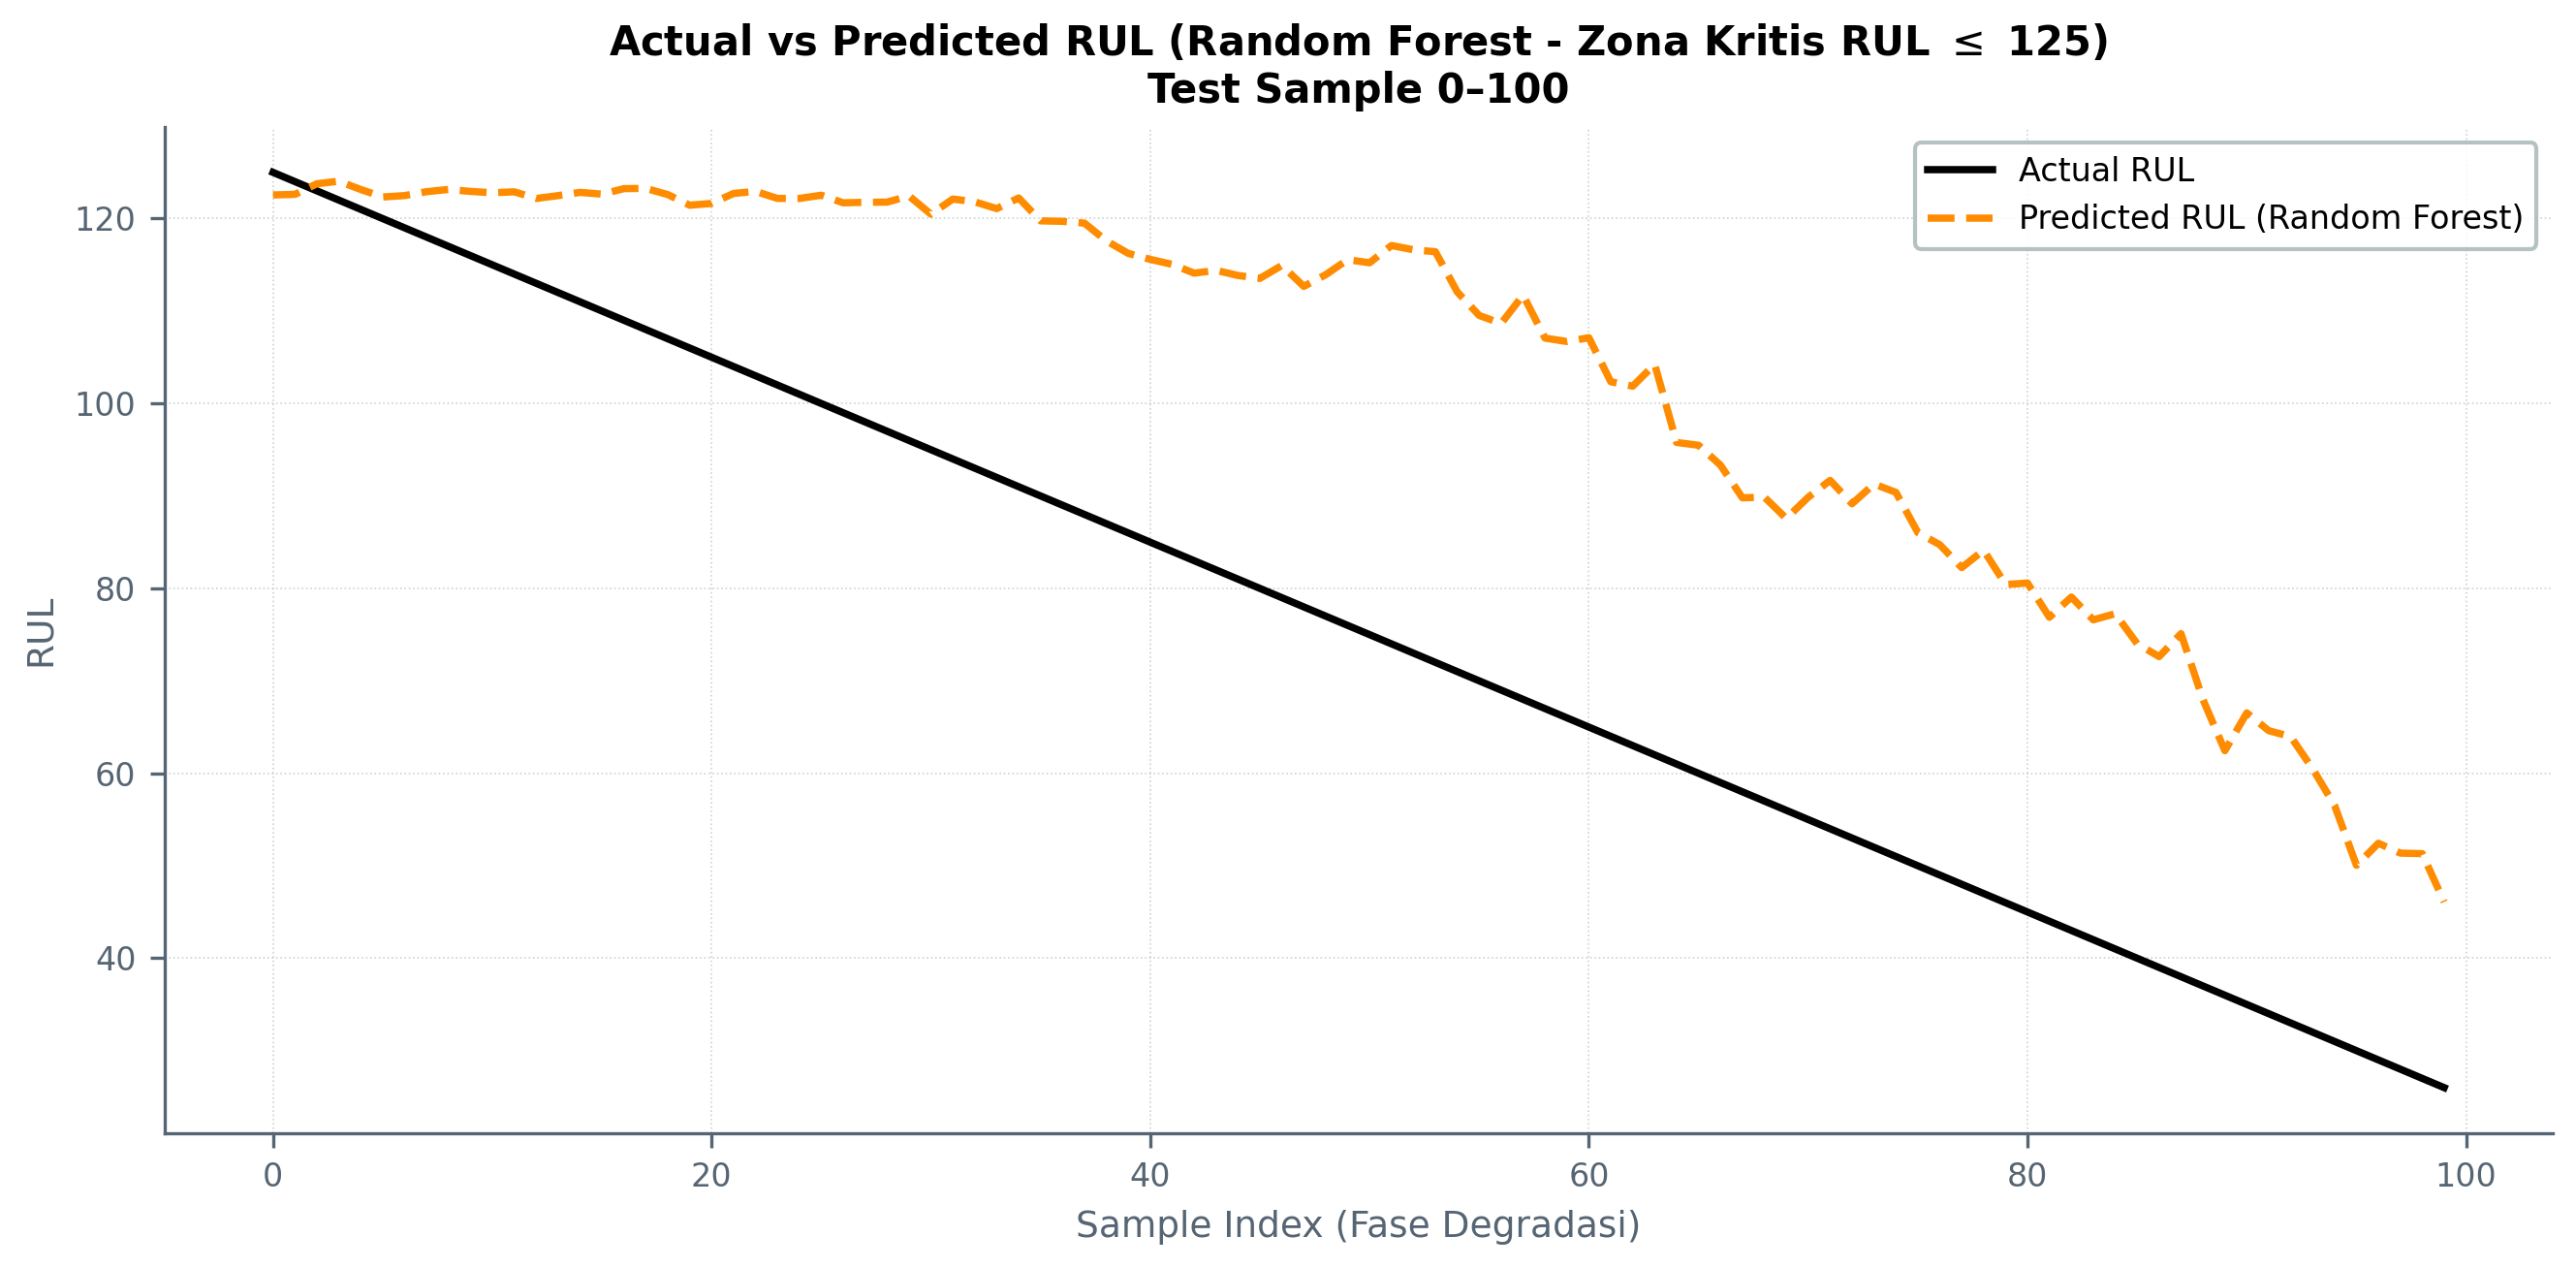

In [8]:
mask_test = y_test <= 125
y_test_filtered = y_test[mask_test]
y_pred_rf_filtered = y_pred_rf_test[mask_test]

N_START = 0
N_END   = 100

plt.figure(figsize=(9, 4.5))

plt.plot(
    range(N_START, N_END),
    y_test_filtered[N_START:N_END],
    color='black',
    linewidth=1.8,
    label='Actual RUL'
)

plt.plot(
    range(N_START, N_END),
    y_pred_rf_filtered[N_START:N_END],
    color='darkorange',
    linestyle='--',
    linewidth=1.8,
    label='Predicted RUL (Random Forest)'
)

plt.title(f'Actual vs Predicted RUL (Random Forest - Zona Kritis RUL $\leq$ 125)\nTest Sample {N_START}–{N_END}')
plt.xlabel('Sample Index (Fase Degradasi)')
plt.ylabel('RUL')
plt.grid(True, linestyle=':', alpha=0.6) 
plt.legend()
plt.tight_layout()

save_plot('RF_timeseries_test_filtered.png') 
plt.show()

<>:8: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:8: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\acer\AppData\Local\Temp\ipykernel_408\497426041.py:8: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  fig.suptitle('Random Forest — Residual Analysis (Zona Kritis RUL $\leq$ 125)',


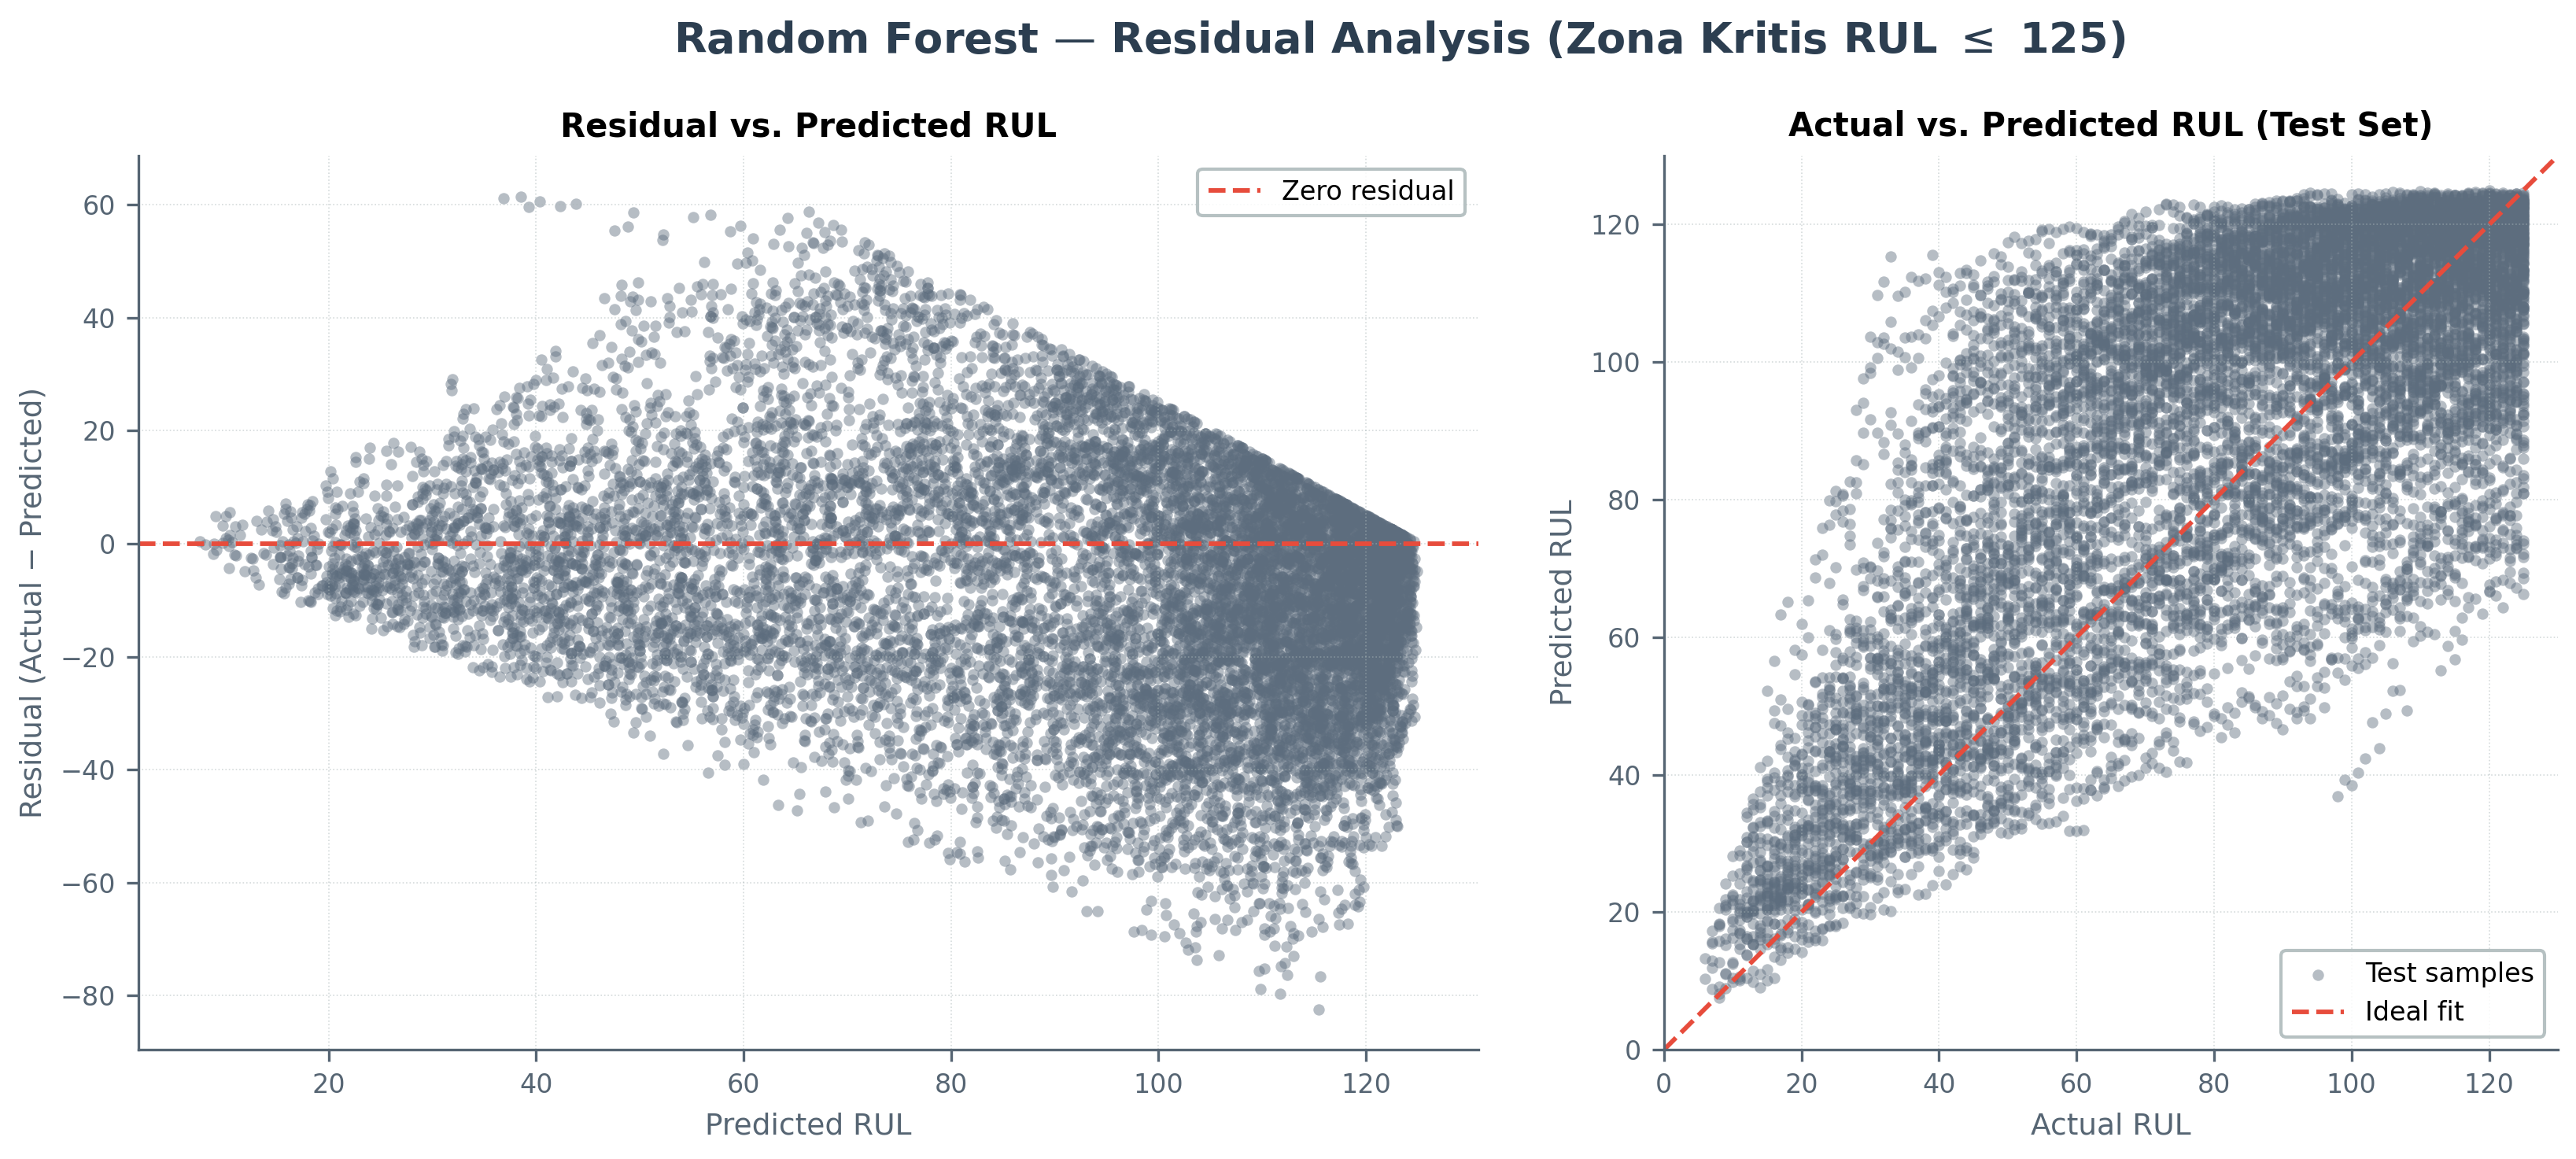

In [9]:
mask_test = y_test <= 125
y_test_filtered = y_test[mask_test]
rf_pred_test_filtered = PREDS_TEST[0][mask_test] 

residuals_rf_filtered = y_test_filtered - rf_pred_test_filtered

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Random Forest — Residual Analysis (Zona Kritis RUL $\leq$ 125)', 
             fontsize=13, fontweight='bold', color='#2C3E50')

DOT_COLOR = '#5D6D7E'
LINE_COLOR = '#E74C3C'

axes[0].scatter(rf_pred_test_filtered, residuals_rf_filtered, 
                color=DOT_COLOR, alpha=0.45, s=12, linewidths=0)
axes[0].axhline(0, color=LINE_COLOR, lw=1.4, 
                linestyle='--', label='Zero residual')
axes[0].set_title('Residual vs. Predicted RUL')
axes[0].set_xlabel('Predicted RUL')
axes[0].set_ylabel('Residual (Actual − Predicted)')
axes[0].grid(True, linestyle=':', alpha=0.5)
axes[0].legend(fontsize=8)

LIM = [0, 130] 
axes[1].scatter(y_test_filtered, rf_pred_test_filtered,
                color=DOT_COLOR, alpha=0.45, s=12, linewidths=0,
                label='Test samples')
axes[1].plot(LIM, LIM, color=LINE_COLOR, lw=1.4, 
             linestyle='--', label='Ideal fit')
axes[1].set_xlim(LIM)
axes[1].set_ylim(LIM)
axes[1].set_title('Actual vs. Predicted RUL (Test Set)')
axes[1].set_xlabel('Actual RUL')
axes[1].set_ylabel('Predicted RUL')
axes[1].set_aspect('equal')
axes[1].grid(True, linestyle=':', alpha=0.5) 
axes[1].legend(fontsize=8)

plt.tight_layout()
save_plot('RF_residual_actual_predicted_filtered.png')
plt.show()

In [10]:
y_test_arr = y_test.values if hasattr(y_test, 'values') else y_test
mask_test = y_test_arr <= 125

y_test_filtered = y_test_arr[mask_test]
y_pred_rf_filtered = y_pred_rf_test[mask_test]

residuals_test_filtered = y_pred_rf_filtered - y_test_filtered


mu_resid = residuals_test_filtered.mean()
sigma_resid = residuals_test_filtered.std(ddof=1)

print(f"── Parameter Residual (RUL <= 125) ──")
print(f"Residual mean (bias)  : {mu_resid:.4f}")
print(f"Residual std (sigma)  : {sigma_resid:.4f}")

stat, p_value = shapiro(residuals_test_filtered)
print(f"Shapiro-Wilk          : stat={stat:.4f}, p-value={p_value:.4f}")

── Parameter Residual (RUL <= 125) ──
Residual mean (bias)  : 8.2955
Residual std (sigma)  : 21.2728
Shapiro-Wilk          : stat=0.9980, p-value=0.0000


c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 11872.
  res = hypotest_fun_out(*samples, **kwds)


<>:6: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:6: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\acer\AppData\Local\Temp\ipykernel_408\4250973149.py:6: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  plt.title('Distribusi Residual Prediksi RUL\n(Random Forest, Test Set FD004 - Zona RUL $\leq$ 125)')


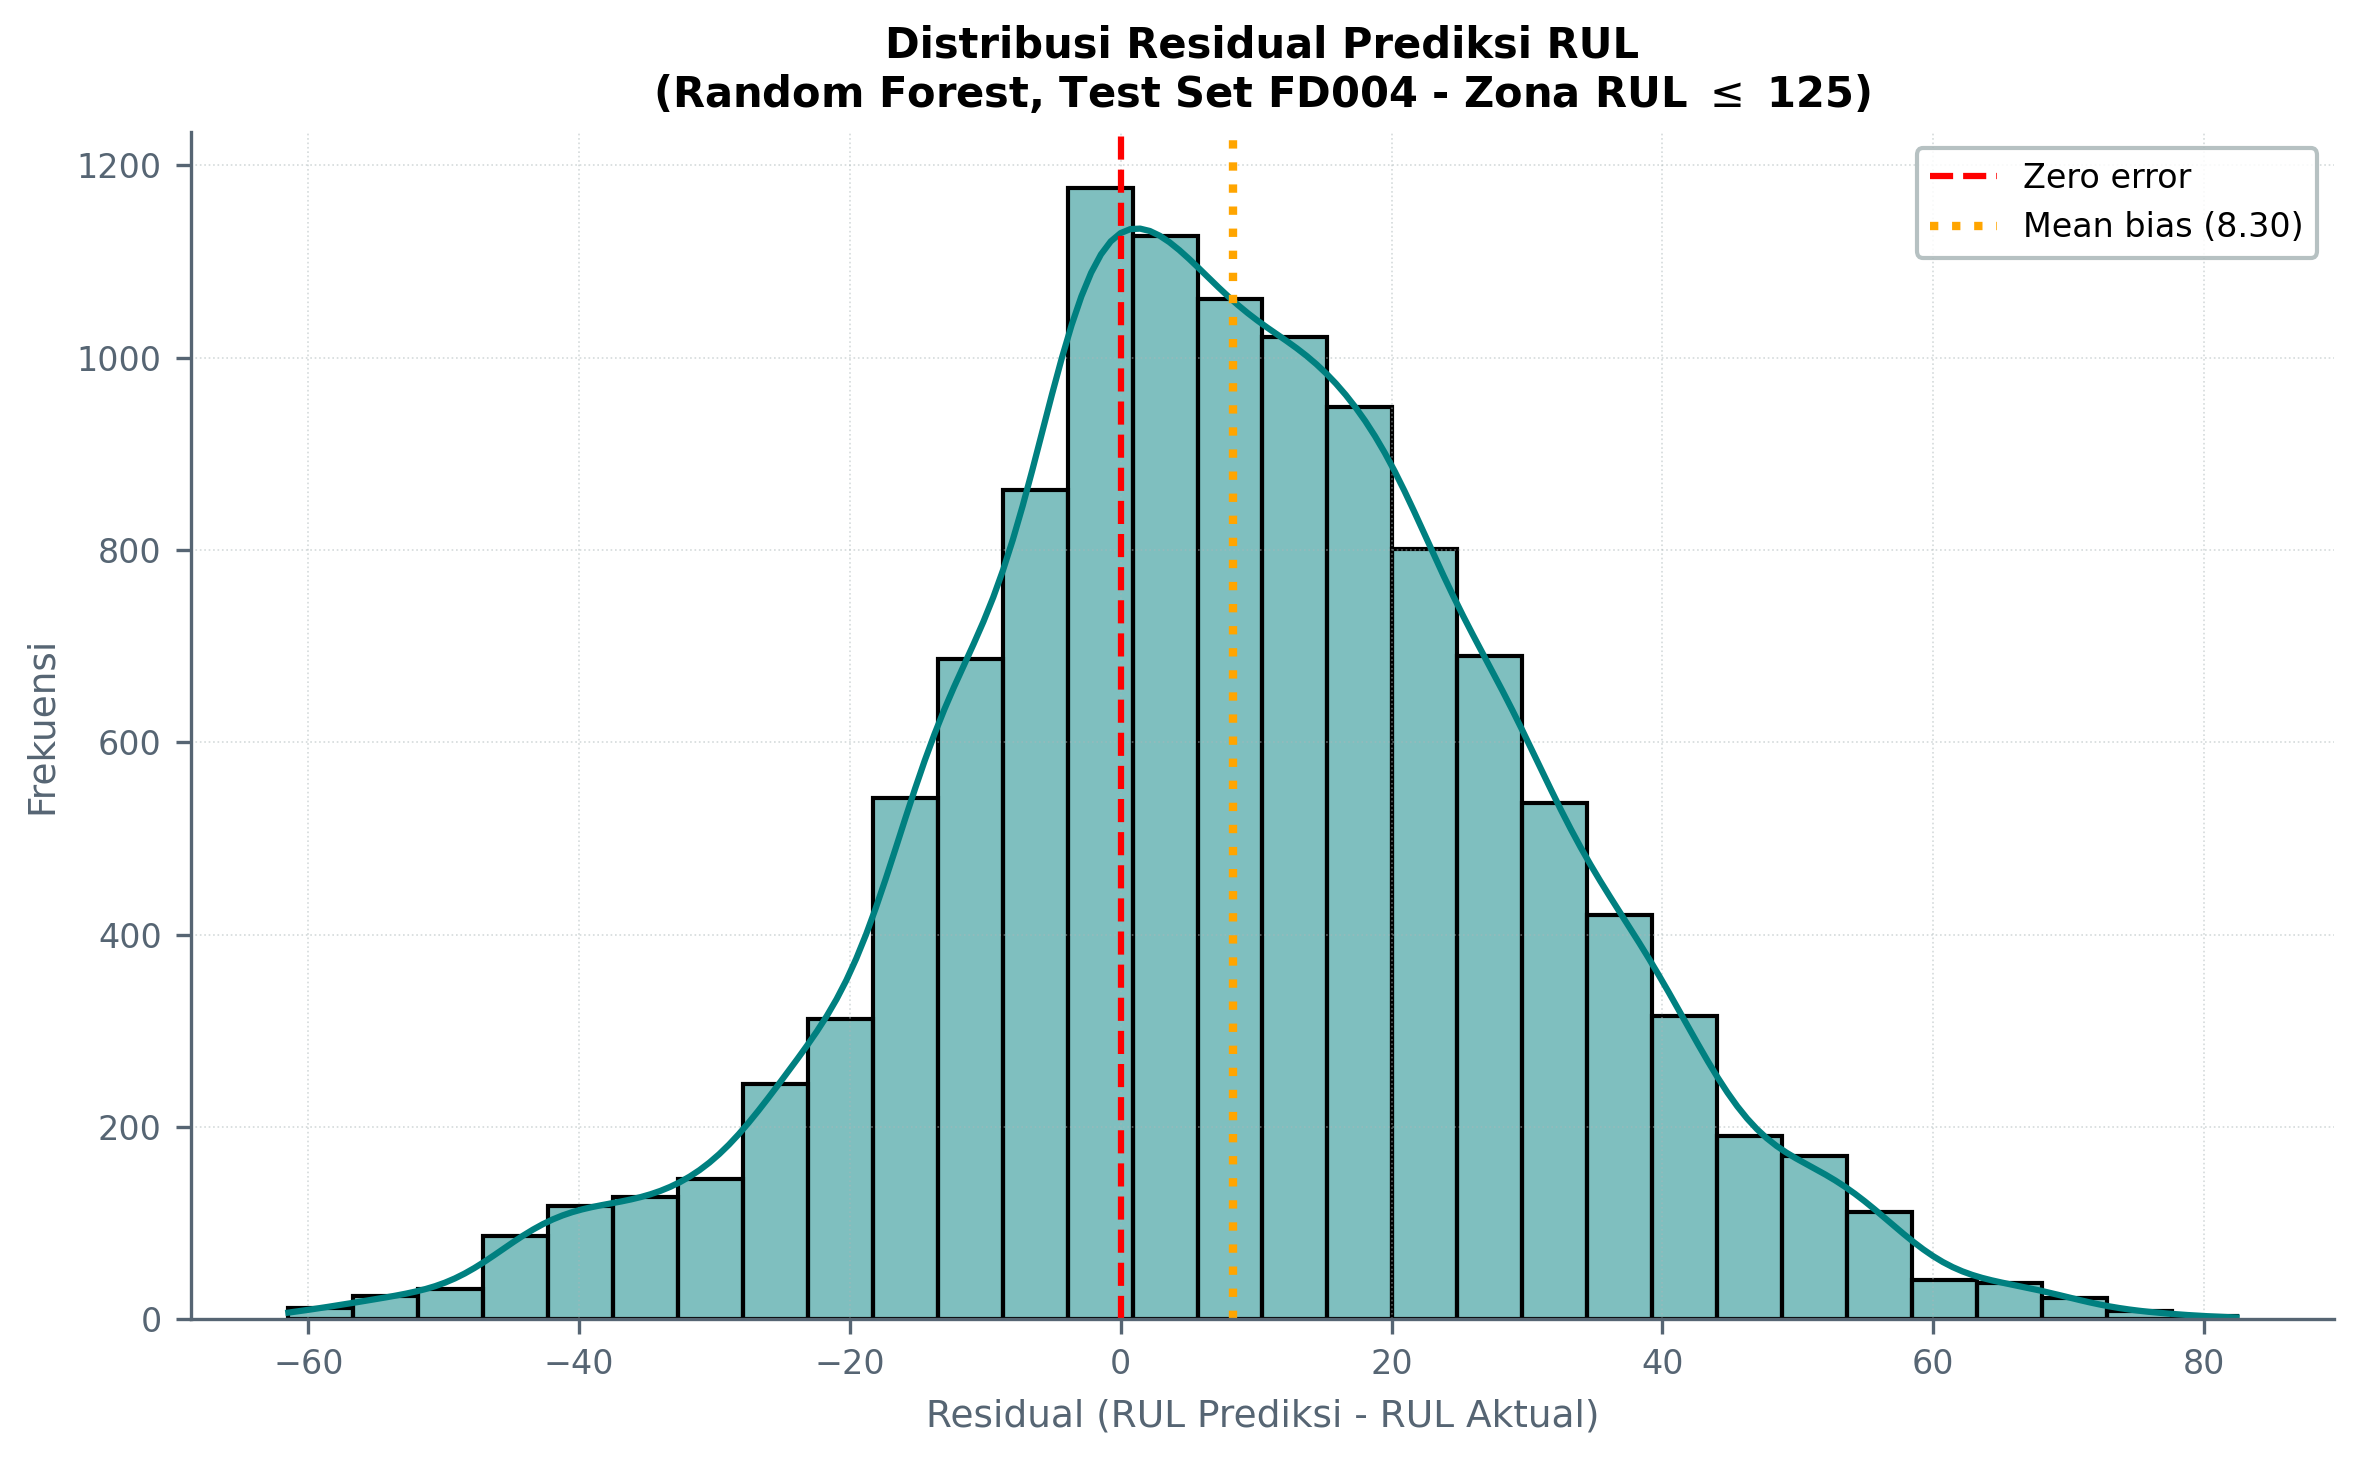

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals_test_filtered, color='teal', kde=True, bins=30)
plt.axvline(0, color='red', linestyle='--', label='Zero error')
plt.axvline(mu_resid, color='orange', linestyle=':', linewidth=2, label=f'Mean bias ({mu_resid:.2f})')

plt.title('Distribusi Residual Prediksi RUL\n(Random Forest, Test Set FD004 - Zona RUL $\leq$ 125)')
plt.xlabel('Residual (RUL Prediksi - RUL Aktual)')
plt.ylabel('Frekuensi')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()

save_plot('residual_distribution_rf_filtered.png')
plt.show()

In [ ]:
DELTA_T = 1
RUL_CAP = 125 

print("\n" + "=" * 55)
print("PARAMETER BIAYA")
print("=" * 55)

Cp = 7_750_000   
MATERIAL_PROPORTION = 0.65
PREMIUM_PCT = 0.625
EXTRA_LEASE_COST = 140_000

PASSENGER_COMP = 57_500
REVENUE_LOSS_AOG = 120_000

Cu_base = Cp + (Cp * MATERIAL_PROPORTION * PREMIUM_PCT) + EXTRA_LEASE_COST
AOG_COST_PER_HOUR = 70_000
AOG_DURATION_HOURS = 24
P_AOG = 0.15

Cu_indirect = P_AOG * (PASSENGER_COMP + REVENUE_LOSS_AOG)
Cu = Cu_base + (P_AOG * AOG_COST_PER_HOUR * AOG_DURATION_HOURS) + Cu_indirect

print(f"Cp            = USD {Cp:>15,.0f}")
print(f"Cu_base       = USD {Cu_base:>15,.0f}")
print(f"Cu (mid)      = USD {Cu:>15,.0f}")
print(f"k = Cu/Cp     = {Cu/Cp:.3f}")

mean_life = train_acq.groupby('unit_id')['cycle'].max().mean()
print(f"\nRata-rata umur mesin (mean_life) : {mean_life:.2f} cycles")

def pF_empirical(M, residuals, delta_t=DELTA_T):
    rul_actual_sim = M - residuals
    return np.mean(rul_actual_sim <= delta_t)

def EC_inf(M, Cp, Cu, residuals, mean_life, delta_t=DELTA_T):
    pF = pF_empirical(M, residuals, delta_t)
    cycle_length = mean_life - M * (1 - pF)
    if cycle_length <= 0:
        return np.inf, pF, cycle_length
    cost = Cp * (1 - pF) + Cu * pF
    return cost / cycle_length, pF, cycle_length

TBM_CYCLES     = 2_100 
FIRST_RUN_INT  = 2_900 
TBM_RATIO      = TBM_CYCLES / FIRST_RUN_INT      
TBM_FD004      = mean_life * TBM_RATIO          

actual_life = (test_acq.groupby('unit_id')['cycle'].max() 
               + test_acq.groupby('unit_id')['RUL'].last())
pF_TBM = np.mean(actual_life.values <= TBM_FD004)
EC_TBM = (Cp * (1 - pF_TBM) + Cu * pF_TBM) / TBM_FD004

print("\n" + "=" * 55)
print("BASELINE TBM")
print("=" * 55)
print(f"TBM interval (FD004 equiv) : {TBM_FD004:.2f} cycles")
print(f"pF_TBM (realistis)         : {pF_TBM:.4f}  ({pF_TBM*100:.2f}%)")
print(f"EC_TBM                     : USD {EC_TBM:,.2f} per cycle")

premium_scenarios = {'low (25%)': 0.25, 'mid (62.5%)': 0.625, 'high (100%)': 1.00}
P_AOG_OPTIONS    = {'low (5%)': 0.05, 'mid (15%)': 0.15, 'high (30%)': 0.30}
M_MIN_OPTIONS    = [5, 10, 20, 35]

results_sensitivity = []
for label_prem, premium in premium_scenarios.items():
    for label_aog, p_aog in P_AOG_OPTIONS.items():
        
        Cu_indirect_s = p_aog * (PASSENGER_COMP + REVENUE_LOSS_AOG)
        
        Cu_s = (Cp 
                + (Cp * MATERIAL_PROPORTION * premium) 
                + EXTRA_LEASE_COST 
                + (p_aog * AOG_COST_PER_HOUR * AOG_DURATION_HOURS)
                + Cu_indirect_s) 

        for M_min in M_MIN_OPTIONS:
            M_range_c = np.arange(M_min, RUL_CAP + 1)
            
            ec_list   = [EC_inf(M, Cp, Cu_s, residuals_test_filtered, mean_life)[0] 
                         for M in M_range_c]
            
            M_star_c  = M_range_c[np.argmin(ec_list)]
            EC_star_c = min(ec_list)
            savings_c = (EC_TBM - EC_star_c) / EC_TBM * 100

            results_sensitivity.append({
                'premium'  : label_prem,
                'P_AOG'    : label_aog,
                'k'        : round(Cu_s / Cp, 3),
                'M_min'    : M_min,
                'M_star'   : M_star_c,
                'EC_star'  : round(EC_star_c, 2),
                'savings_%': round(savings_c, 2)
            })

sensitivity_df = pd.DataFrame(results_sensitivity)

print("\n" + "=" * 55)
print("HASIL SENSITIVITY ANALYSIS (36 SKENARIO)")
print("=" * 55)
print(sensitivity_df.to_string(index=False))

print(f"\nRange savings: {sensitivity_df['savings_%'].min()}% - {sensitivity_df['savings_%'].max()}%")

print("\n=== Driver utama: premium (k) ===")
print(sensitivity_df.groupby('premium')['savings_%'].agg(['min', 'max', 'mean']).round(2))

print("\n=== Driver sekunder: P_AOG (marginal) ===")
print(sensitivity_df.groupby('P_AOG')['savings_%'].agg(['min', 'max', 'mean']).round(2))

sensitivity_df.to_csv(
    r'D:/Research Paper/Data/sensitivity2.csv', 
    index=False
)
print("\nFile berhasil diperbarui & disimpan: sensitivity2.csv")


PARAMETER BIAYA
Cp            = USD       7,750,000
Cu_base       = USD      11,038,438
Cu (mid)      = USD      11,317,062
k = Cu/Cp     = 1.460

Rata-rata umur mesin (mean_life) : 245.98 cycles

BASELINE TBM
TBM interval (FD004 equiv) : 178.12 cycles
pF_TBM (realistis)         : 0.1855  (18.55%)
EC_TBM                     : USD 47,223.63 per cycle

HASIL SENSITIVITY ANALYSIS (36 SKENARIO)
    premium      P_AOG     k  M_min  M_star  EC_star  savings_%
  low (25%)   low (5%) 1.193      5      11 35129.23      25.61
  low (25%)   low (5%) 1.193     10      11 35129.23      25.61
  low (25%)   low (5%) 1.193     20      20 35338.83      25.17
  low (25%)   low (5%) 1.193     35      35 36843.75      21.98
  low (25%)  mid (15%) 1.217      5      13 35458.13      24.91
  low (25%)  mid (15%) 1.217     10      13 35458.13      24.91
  low (25%)  mid (15%) 1.217     20      20 35579.27      24.66
  low (25%)  mid (15%) 1.217     35      35 36943.01      21.77
  low (25%) high (30%) 1.252 

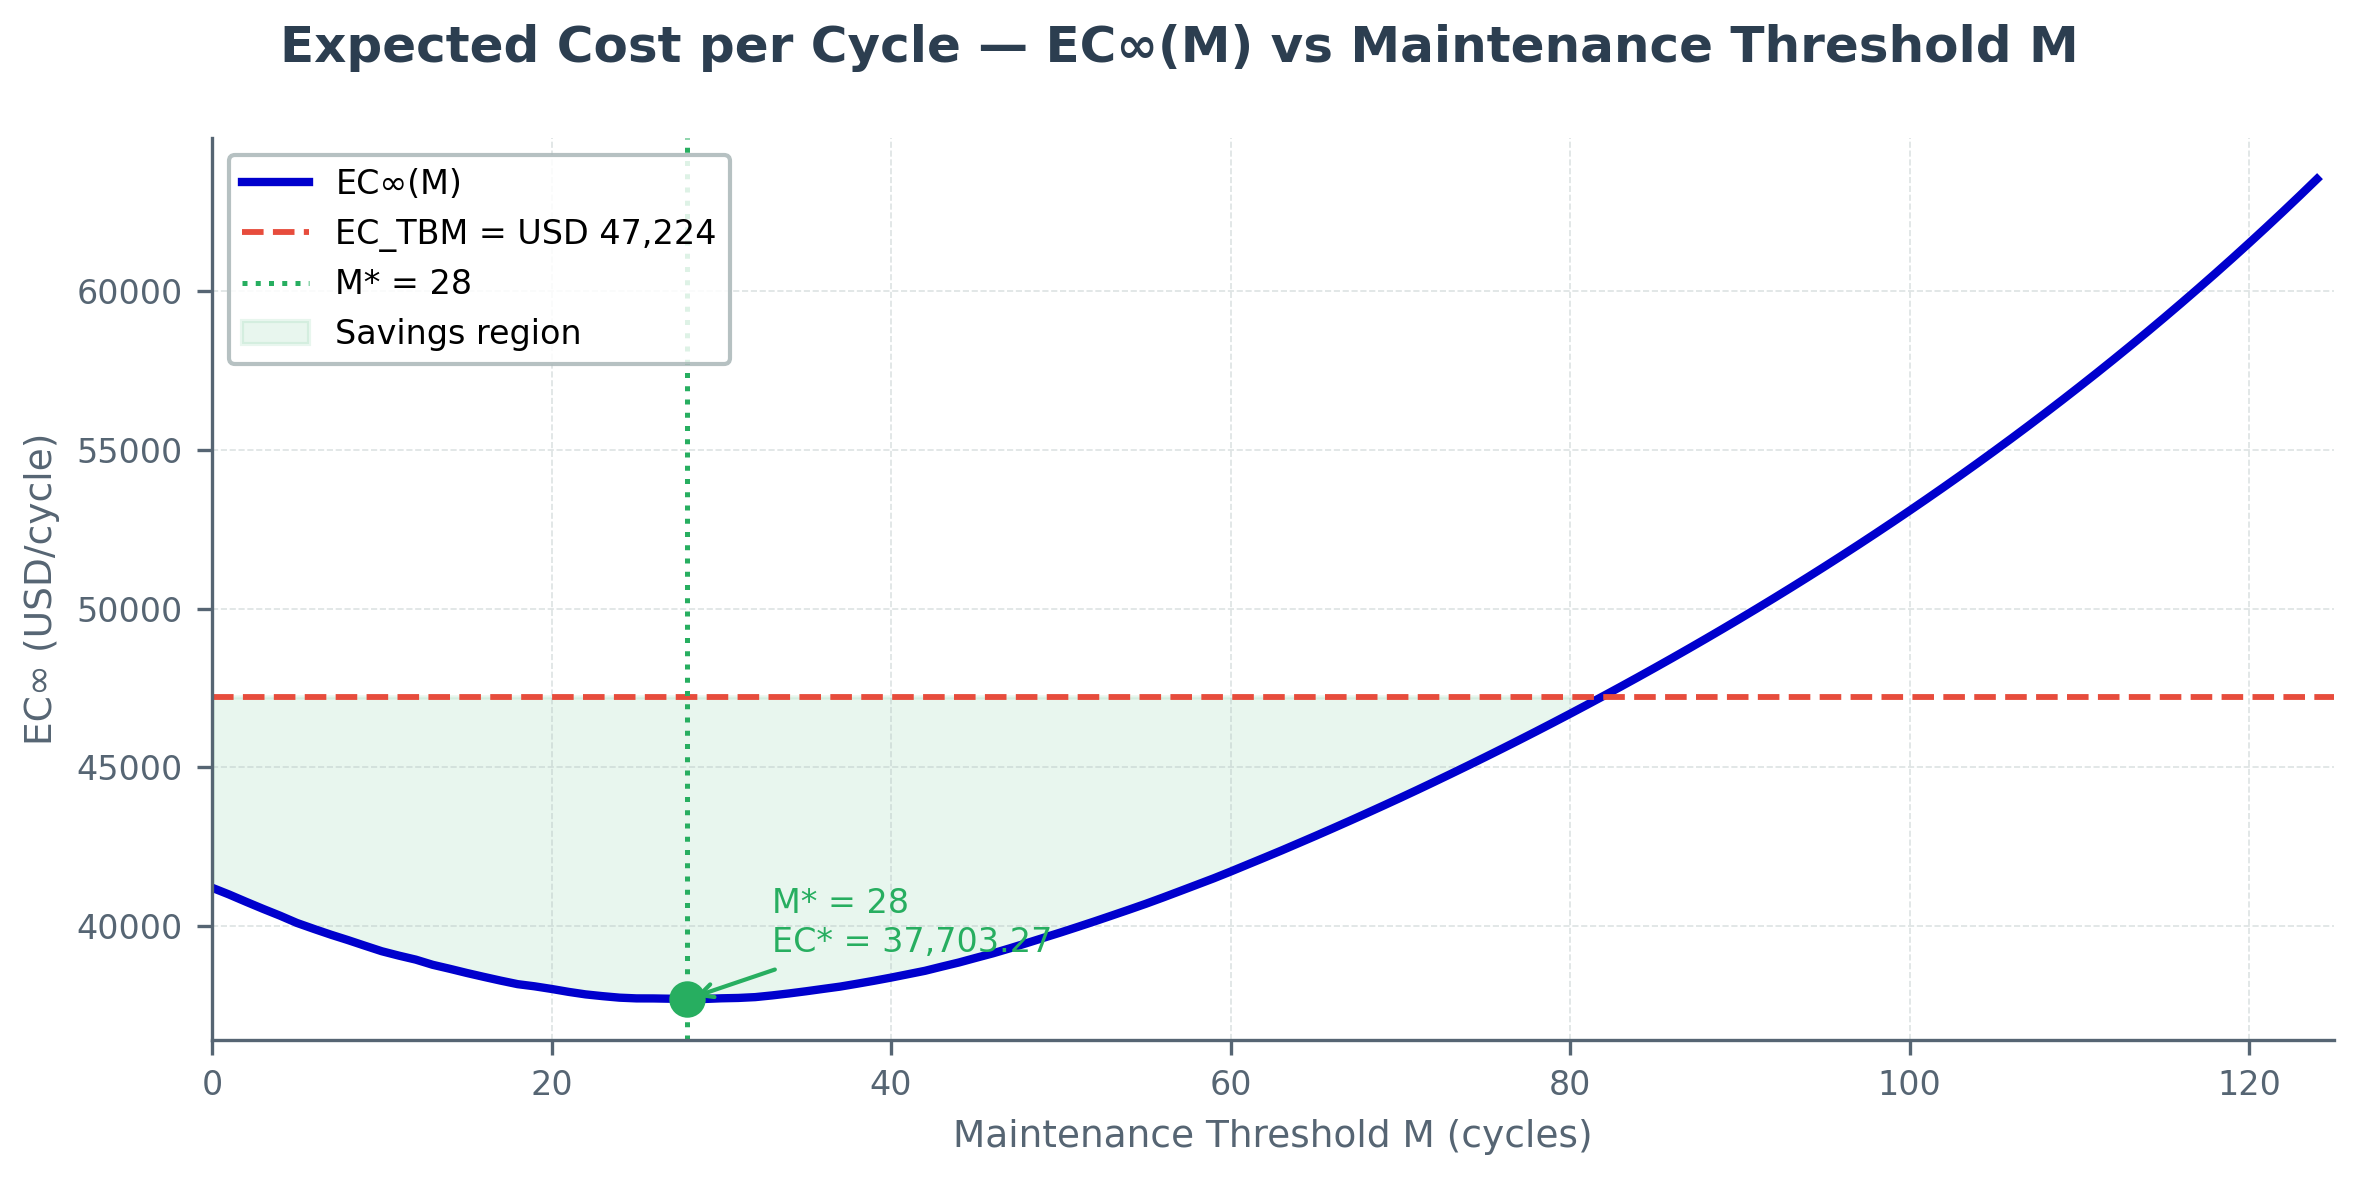

In [16]:
M_plot = np.arange(0, 125, 1)
ec_plot = [EC_inf(M, Cp, Cu, residuals_test_filtered, mean_life)[0] for M in 
M_plot]
pf_plot = [EC_inf(M, Cp, Cu, residuals_test_filtered, mean_life)[1] for M in 
M_plot]
M_star = M_plot[np.argmin(ec_plot)]
EC_star = min(ec_plot)
fig, ax = plt.subplots(figsize=(8, 4))
fig.suptitle('Expected Cost per Cycle — EC∞(M) vs Maintenance Threshold M',
             fontsize=12, fontweight='bold', color='#2C3E50')
ax.plot(M_plot, ec_plot, color=NAVY, lw=2.0, label='EC∞(M)')
ax.axhline(EC_TBM, color=RED, lw=1.4, linestyle='--', label=f'EC_TBM = USD {EC_TBM:,.0f}')
ax.axvline(M_star, color=GREEN, lw=1.2, linestyle=':', label=f'M* = {M_star}')
ax.scatter([M_star], [EC_star], color=GREEN, s=60, zorder=5)
ax.annotate(f'M* = {M_star}\nEC* = {EC_star:,.2f}',
            xy=(M_star, EC_star),
            xytext=(M_star + 5, EC_star + 1500),
            fontsize=8, color=GREEN,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.0))

ax.fill_between(M_plot, ec_plot, EC_TBM,
                where=np.array(ec_plot) < EC_TBM,
                alpha=0.10, color=GREEN, label='Savings region')
ax.set_xlabel('Maintenance Threshold M (cycles)')
ax.set_ylabel('EC∞ (USD/cycle)')
ax.legend(loc='upper left')
ax.set_xlim(0, 125)
save_plot('opt_ec_inf_curve.png')

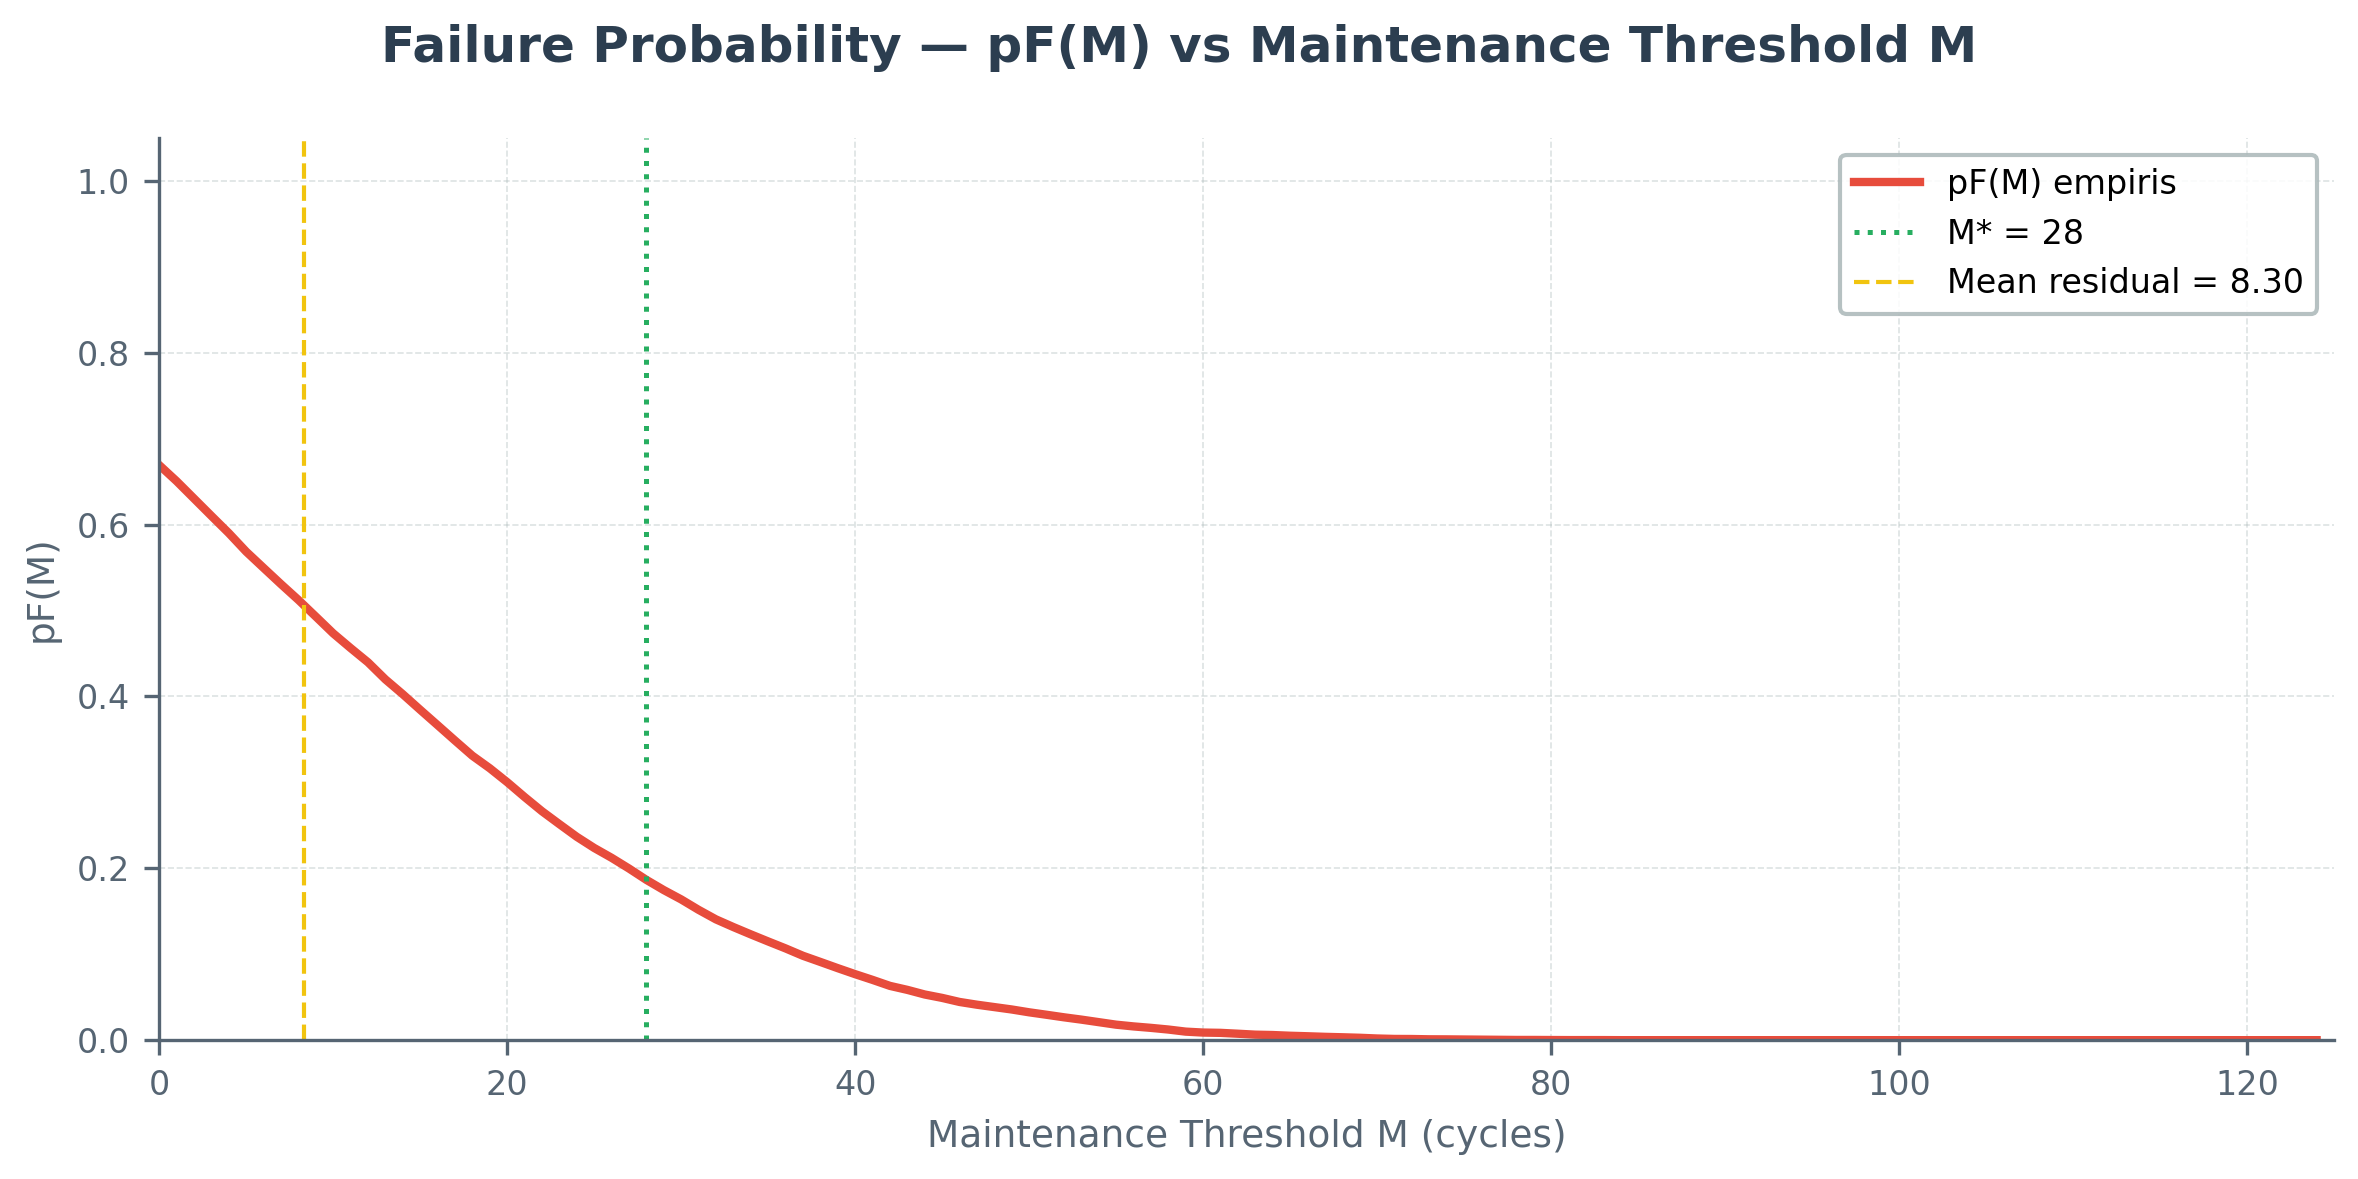

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
fig.suptitle('Failure Probability — pF(M) vs Maintenance Threshold M',
             fontsize=12, fontweight='bold', color='#2C3E50')
ax.plot(M_plot, pf_plot, color=RED, lw=2.0, label='pF(M) empiris')
ax.axvline(M_star, color=GREEN, lw=1.2, linestyle=':', label=f'M* = {M_star}')
ax.axvline(8.3, color=YELLOW, lw=1.0, linestyle='--',
           label=f'Mean residual = 8.30')
ax.set_xlabel('Maintenance Threshold M (cycles)')

ax.set_ylabel('pF(M)')
ax.set_xlim(0, 125)
ax.set_ylim(0, 1.05)
ax.legend(loc='upper right')
save_plot('opt_pf_curve.png')

In [ ]:
check_points = [0, 8, 10, 20, 28, 35, 40, 50, 60, 65, 70, 80, 100, 120]

print("=" * 45)
print(f"{'M':>5} | {'pF(M)':>10} | {'exact 0?':>10}")
print("=" * 45)
for m in check_points:
    pf_val = pF_empirical(m, residuals_test_filtered, DELTA_T)
    is_zero = "YA" if pf_val == 0.0 else "tidak"
    print(f"{m:>5} | {pf_val:>10.6f} | {is_zero:>10}")

M_range_full = np.arange(0, 126)
pf_full = np.array([pF_empirical(m, residuals_test_filtered, DELTA_T) for m in M_range_full])
zero_idx = np.where(pf_full == 0.0)[0]
if len(zero_idx) > 0:
    first_zero_M = M_range_full[zero_idx[0]]
    print(f"\npF(M) pertama kali TEPAT 0 pada M = {first_zero_M}")
else:
    print("\npF(M) tidak pernah tepat 0 di rentang M yang diuji (hanya mendekati).")

    M |      pF(M) |   exact 0?
    0 |   0.669306 |      tidak
    8 |   0.512382 |      tidak
   10 |   0.473467 |      tidak
   20 |   0.300286 |      tidak
   28 |   0.186573 |      tidak
   35 |   0.114892 |      tidak
   40 |   0.076819 |      tidak
   50 |   0.032429 |      tidak
   60 |   0.008844 |      tidak
   65 |   0.005138 |      tidak
   70 |   0.001937 |      tidak
   80 |   0.000168 |      tidak
  100 |   0.000000 |         YA
  120 |   0.000000 |         YA

pF(M) pertama kali TEPAT 0 pada M = 84


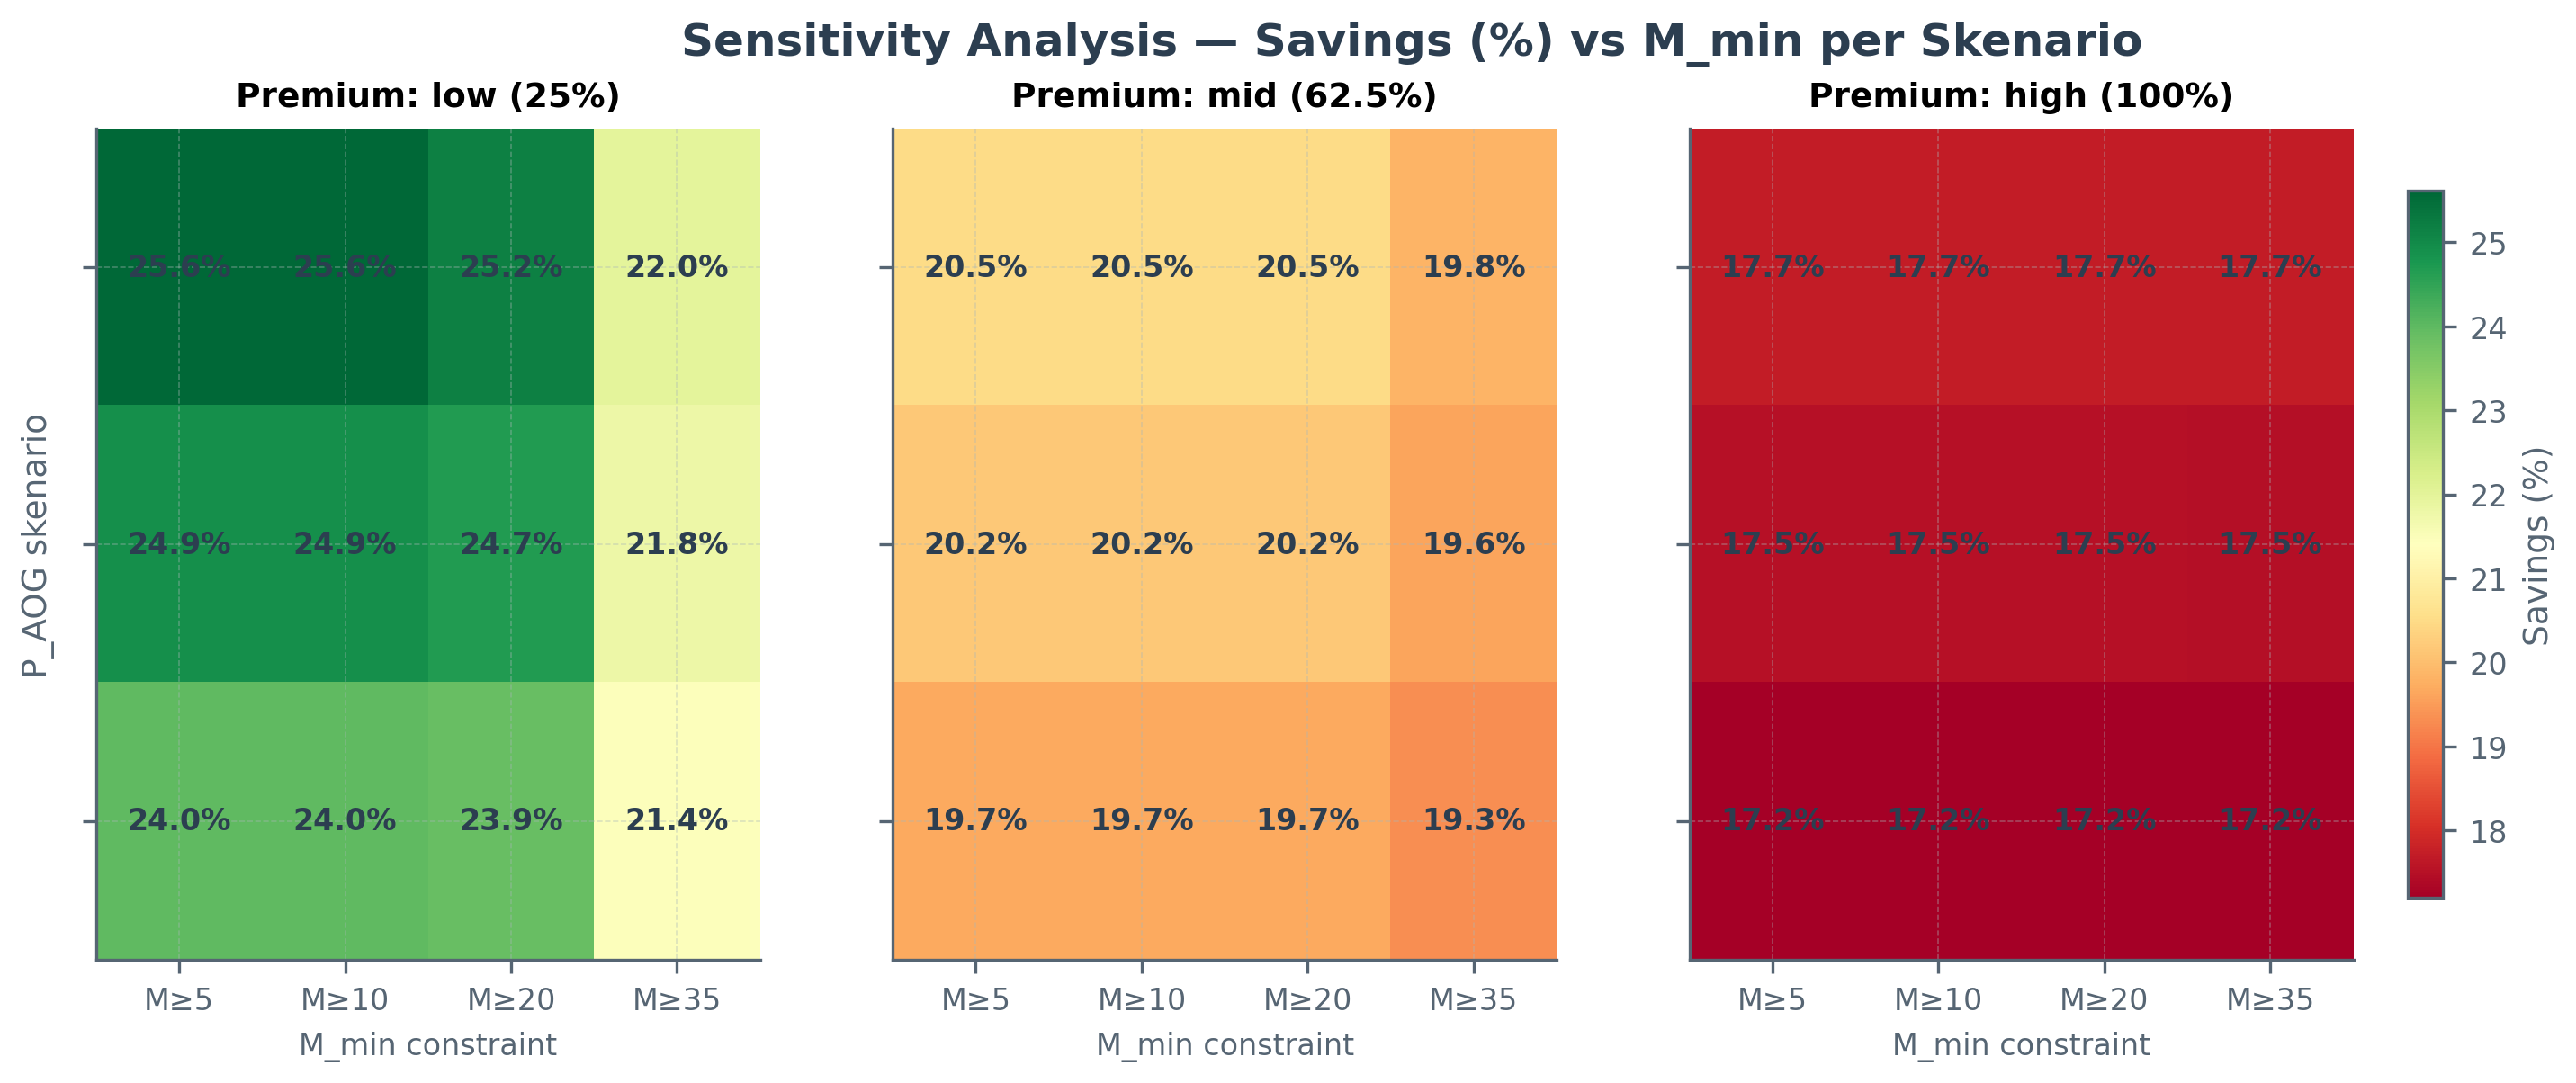

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
fig.suptitle('Sensitivity Analysis — Savings (%) vs M_min per Skenario',
             fontsize=12, fontweight='bold', color='#2C3E50')
premiums = sensitivity_df['premium'].unique()
M_mins   = sorted(sensitivity_df['M_min'].unique())
p_aogs   = sensitivity_df['P_AOG'].unique()
cmap = plt.cm.RdYlGn
vmin = sensitivity_df['savings_%'].min()
vmax = sensitivity_df['savings_%'].max()
for ax, prem in zip(axes, premiums):
    df_sub = sensitivity_df[sensitivity_df['premium'] == prem]
    matrix = df_sub.pivot(index='P_AOG', columns='M_min', 
values='savings_%')
    matrix = matrix.loc[p_aogs, M_mins]
    im = ax.imshow(matrix.values, cmap=cmap,
                   vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(len(M_mins)))
    ax.set_xticklabels([f'M≥{m}' for m in M_mins], fontsize=8)
    ax.set_yticks(range(len(p_aogs)))
    ax.set_yticklabels(p_aogs if ax == axes[0] else [], fontsize=8)
    ax.set_title(f'Premium: {prem}', fontsize=9)
    ax.set_xlabel('M_min constraint', fontsize=8)
    for i in range(len(p_aogs)):
        for j in range(len(M_mins)):
            ax.text(j, i, f"{matrix.values[i, j]:.1f}%",
                    ha='center', va='center',
                    fontsize=8, color='#2C3E50', fontweight='bold')
axes[0].set_ylabel('P_AOG skenario', fontsize=9)
cbar = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label('Savings (%)', fontsize=9)
cbar.ax.tick_params(labelsize=8)
def save_plot_heatmap(filename):
    plt.savefig(os.path.join(plot_dir, filename), dpi=300, 
bbox_inches='tight')
    plt.show()
save_plot_heatmap('opt_sensitivity_heatmap.png')